Author: <font color="#2680EB">Anna Quílez Rodríguez</font>

E-mail: <font color="#2680EB">anna.quilez01@estudiant.upf.edu</font>

AI used: <font color="#2680EB" >ChatGPT. I used artificial intelligence to help me understand the functions I wasn’t familiar with and to write some of the code.</font>

Date: <font color="#2680EB">25/11/2026</font>

In [1]:
import io
import json
import pandas as pd
import datetime
import numpy as np
import scipy.stats as stats
import math

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


# 0. Dataset

In [2]:
# LEAVE AS-IS

INPUT_FILE = "aemet-barcelona-airport-2016-2026.json"
weather = pd.read_json(INPUT_FILE)

display(weather.head(5))
display(weather.tail(5))

,fecha,indicativo,nombre,provincia,altitud,tmed,prec,tmin,horatmin,tmax,...,horaPresMax,presMin,horaPresMin,hrMedia,hrMax,horaHrMax,hrMin,horaHrMin,pintMax,horaPIntMax
0,2016-07-01,0201D,BARCELONA,BARCELONA,6,"24,1","0,0","21,9",03:40,"26,3",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-07-02,0201D,BARCELONA,BARCELONA,6,"24,6","0,0","22,3",04:40,"27,0",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-07-03,0201D,BARCELONA,BARCELONA,6,"23,4","0,0","21,9",11:00,"24,9",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-04,0201D,BARCELONA,BARCELONA,6,"23,8","0,0","21,8",04:40,"25,9",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-05,0201D,BARCELONA,BARCELONA,6,"25,3","0,0","23,2",00:10,"27,4",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,fecha,indicativo,nombre,provincia,altitud,tmed,prec,tmin,horatmin,tmax,...,horaPresMax,presMin,horaPresMin,hrMedia,hrMax,horaHrMax,hrMin,horaHrMin,pintMax,horaPIntMax
3725,2026-09-14,0076,BARCELONA AEROPUERTO,BARCELONA,1,"24,4","0,0","19,7",05:29,"29,1",...,Varias,"1018,7",16,67.0,83.0,Varias,46.0,10:44,"0,0",NaN
3726,2026-09-15,0076,BARCELONA AEROPUERTO,BARCELONA,1,"26,3","0,0","21,3",05:30,"31,3",...,Varias,"1016,5",16,56.0,68.0,Varias,37.0,09:32,"0,0",NaN
3727,2026-09-16,0076,BARCELONA AEROPUERTO,BARCELONA,1,"23,5","48,0","18,0",21:25,"29,0",...,Varias,"1015,4",16,66.0,94.0,23:05,53.0,07:44,"112,2",21:20
3728,2026-09-17,0076,BARCELONA AEROPUERTO,BARCELONA,1,"22,2","1,1","18,5",00:35,"25,8",...,Varias,"1014,8",18,69.0,94.0,00:32,56.0,11:08,"-0,3",Varias
3729,2026-09-18,0076,BARCELONA AEROPUERTO,BARCELONA,1,"22,2",Ip,"19,0",05:31,"25,5",...,Varias,"1015,0",03,71.0,89.0,04:39,56.0,11:23,"6,0",02:20


In [3]:
# LEAVE AS-IS

COLUMN_NAMES = {
  "fecha" : "date",
  "indicativo" : "station_num",
  "nombre" : "station_name",
  "provincia" : "station_province",
  "altitud" : "station_altitude",
  "tmed" : "temp_avg",
  "tmin" : "temp_min",
  "tmax" : "temp_max",
  "horatmin" : "temp_min_time",
  "horatmax" : "temp_max_time",
  "prec" : "rainfall",
  "dir" : "windspeed_dir",
  "velmedia" : "windspeed_avg",
  "racha" : "windspeed_gusts",
  "horaracha" : "windspeed_gusts_time",
  "sol" : "sun",
  "presMax" : "pressure_max",
  "horaPresMax" : "pressure_max_time",
  "presMin" : "pressure_min",
  "horaPresMin" : "pressure_min_time",
  "hrMedia": "relhumidity_mean",
  "hrMax": "relhumidity_max",
  "hrMin": "relhumidity_min",
  "horaHrMax": "relhumidity_max_time", 
  "horaHrMin": "relhumidity_min_time"
}

weather_renamed = weather.copy()
weather_renamed.rename(columns=COLUMN_NAMES, inplace=True)
list(weather_renamed.columns)

['date',
 'station_num',
 'station_name',
 'station_province',
 'station_altitude',
 'temp_avg',
 'rainfall',
 'temp_min',
 'temp_min_time',
 'temp_max',
 'temp_max_time',
 'windspeed_dir',
 'windspeed_avg',
 'windspeed_gusts',
 'windspeed_gusts_time',
 'sun',
 'pressure_max',
 'pressure_max_time',
 'pressure_min',
 'pressure_min_time',
 'relhumidity_mean',
 'relhumidity_max',
 'relhumidity_max_time',
 'relhumidity_min',
 'relhumidity_min_time',
 'pintMax',
 'horaPIntMax']

# 1. Preparation

## 1.1. Cleaning <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Answer the following question.**</font>

**Answer:**

We will remove the columns station_num, station_name, station_province, station_altitude. Why?

* We remove these columns because they contain information about the weather station rather than daily weather measurements. Since all the data comes from the same place (Barcelona Airport), these values remain constant and do not provide useful information for analysing or predicting changes in the weather. Removing them allows us to focus on the actual meteorological variables.

<font size="+1" color="#2680EB">**Remove the station number, name, province, and altitude columns, plus all the _time columns.**</font>

In [4]:
weather_column_sel = weather_renamed.copy()

# YOUR ANSWER HERE
# AI assistance was used to identify and select the columns to remove.
weather_column_sel.drop(
    columns=[
        'station_num',
        'station_name',
        'station_province',
        'station_altitude',
        'temp_min_time',
        'temp_max_time',
        'windspeed_gusts_time',
        'pressure_max_time',
        'pressure_min_time',
        'relhumidity_max_time',
        'relhumidity_min_time'
    ],
    inplace=True
)

In [5]:
# LEAVE THIS CODE AS-IS

display(weather_column_sel.head(5))
display(weather_column_sel.tail(5))

,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
0,2016-07-01,"24,1","0,0","21,9","26,3",99.0,"3,1","5,8",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-07-02,"24,6","0,0","22,3","27,0",13.0,"3,6","7,5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-07-03,"23,4","0,0","21,9","24,9",20.0,"4,2","8,9",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-04,"23,8","0,0","21,8","25,9",25.0,"3,3","6,7",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-05,"25,3","0,0","23,2","27,4",35.0,"3,1","6,4",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
3725,2026-09-14,"24,4","0,0","19,7","29,1",23.0,"6,7","12,5","11,4","1022,0","1018,7",67.0,83.0,46.0,"0,0",NaN
3726,2026-09-15,"26,3","0,0","21,3","31,3",22.0,"4,7","10,3","11,5","1019,5","1016,5",56.0,68.0,37.0,"0,0",NaN
3727,2026-09-16,"23,5","48,0","18,0","29,0",3.0,"4,7","15,0","6,0","1019,7","1015,4",66.0,94.0,53.0,"112,2",21:20
3728,2026-09-17,"22,2","1,1","18,5","25,8",24.0,"4,2","10,8","3,8","1017,9","1014,8",69.0,94.0,56.0,"-0,3",Varias
3729,2026-09-18,"22,2",Ip,"19,0","25,5",19.0,"3,6","8,9","7,0","1019,6","1015,0",71.0,89.0,56.0,"6,0",02:20


<font size="+1" color="#2680EB">**Implement function aemet_cleanup,** which should perform the actions 1, 2, 3 above.</font>

In [6]:
def aemet_cleanup(x):
    val = str(x)

    # YOUR ANSWER HERE
    # Convert negligible rainfall into zero
    if val == "Ip":
        return 0.0
    
    # Replace decimal commas with dots
    val = val.replace(",", ".")
    
    # Convert the value to a float, returning NaN if it is not numeric
    try:
        return float(val)
    except ValueError:
        return np.nan
    

<font size="+1" color="#2680EB">**Implement tests for your function aemet_cleanup.**</font>

In [9]:
assert np.isnan(aemet_cleanup(""))
assert 0.0 == aemet_cleanup("0,0")
assert 0.0 == aemet_cleanup("Ip")

# Add more cases below

# YOUR ANSWER HERE
# Additional tests by AI 
assert np.isnan(aemet_cleanup("Varias"))
assert np.isnan(aemet_cleanup("06:30"))
assert 13.5 == aemet_cleanup("13,5")
assert 13.0 == aemet_cleanup("13")



<font size="+1" color="#2680EB">**Apply the cleanup function to these columns:** 'temp_min', 'temp_max', 'temp_avg', 'rainfall', 'windspeed_dir', 'windspeed_avg', 'windspeed_gusts', 'pressure_min', 'pressure_max', 'relhumidity_min', 'relhumidity_max' </font>

In [15]:
weather_clean = weather_column_sel.copy()

# YOUR ANSWER HERE
# Apply the cleaning function to all numerical weather columns
numerical_columns = [
    'temp_min',
    'temp_max',
    'temp_avg',
    'rainfall',
    'windspeed_dir',
    'windspeed_avg',
    'windspeed_gusts',
    'pressure_min',
    'pressure_max',
    'relhumidity_min',
    'relhumidity_max'
]

# Apply the cleaning function to all numerical columns

for column in numerical_columns:
    weather_clean[column] = weather_clean[column].apply(aemet_cleanup)


In [16]:
# LEAVE THIS CODE AS-IS

display(weather_clean.head(5))
display(weather_clean.tail(5))

,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
0,2016-07-01,24.1,0.0,21.9,26.3,99.0,3.1,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-07-02,24.6,0.0,22.3,27.0,13.0,3.6,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-07-03,23.4,0.0,21.9,24.9,20.0,4.2,8.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-07-04,23.8,0.0,21.8,25.9,25.0,3.3,6.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-07-05,25.3,0.0,23.2,27.4,35.0,3.1,6.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,date,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
3725,2026-09-14,24.4,0.0,19.7,29.1,23.0,6.7,12.5,"11,4",1022.0,1018.7,67.0,83.0,46.0,"0,0",NaN
3726,2026-09-15,26.3,0.0,21.3,31.3,22.0,4.7,10.3,"11,5",1019.5,1016.5,56.0,68.0,37.0,"0,0",NaN
3727,2026-09-16,23.5,48.0,18.0,29.0,3.0,4.7,15.0,"6,0",1019.7,1015.4,66.0,94.0,53.0,"112,2",21:20
3728,2026-09-17,22.2,1.1,18.5,25.8,24.0,4.2,10.8,"3,8",1017.9,1014.8,69.0,94.0,56.0,"-0,3",Varias
3729,2026-09-18,22.2,0.0,19.0,25.5,19.0,3.6,8.9,"7,0",1019.6,1015.0,71.0,89.0,56.0,"6,0",02:20


 ## 1.2. Index by date and plotting <font color="#2680EB">[10%]</font>

In [17]:
# LEAVE AS-IS

weather_indexed = weather_clean.copy()

weather_indexed.set_index('date', inplace=True)
weather_indexed.index = pd.to_datetime(weather_indexed.index)
display(weather_indexed.head(3))

,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
date,,,,,,,,,,,,,,,
2016-07-01,24.1,0.0,21.9,26.3,99.0,3.1,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-02,24.6,0.0,22.3,27.0,13.0,3.6,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-03,23.4,0.0,21.9,24.9,20.0,4.2,8.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
# LEAVE THIS CELL AS-IS

# Configure font sizes
plt.rc('font', size=10) 
plt.rc('axes', labelsize=16)
plt.rc('legend', fontsize=16)

# Flexible plotting function
def plot_min_max(df, min_col='', max_col='', avg_col='', avg_label='Average', 
                     title='Weather', xlabel='Date', ylabel='Variable'):

    # The instructor used Gemini to create this plot using seaborn
    
    # Apply Seaborn aesthetic theme
    sns.set_theme(style='whitegrid')

    # Create figure and axis
    plt.figure(figsize=(16, 5))

    # Fill region between min and max
    if min_col and max_col:
        plt.fill_between(df.index, df[min_col], df[max_col], color='lightgray', alpha=0.5)

    # Plot average line using Seaborn
    if avg_col:
        sns.lineplot(data=df, x=df.index, y=avg_col, color='black', label=avg_label)

    # Label axis and title
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.show()
    
# Plot function
def plot_variable(df, col='', label='', title='Weather', xlabel='Date', ylabel=''):
    
    plot_min_max(df, title=title, xlabel=xlabel, ylabel=ylabel, avg_col=col, avg_label=label)

    plt.show()


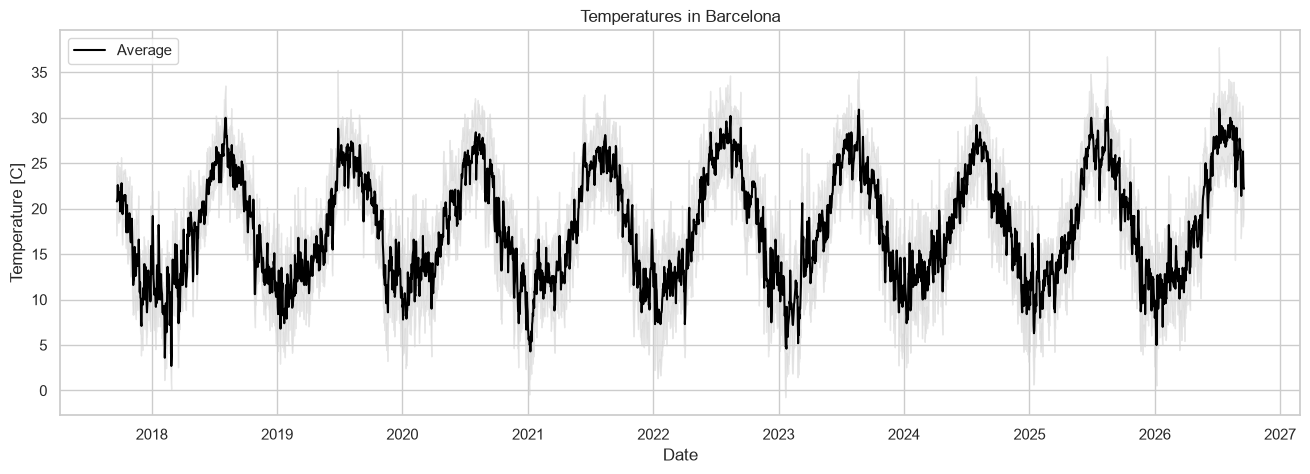

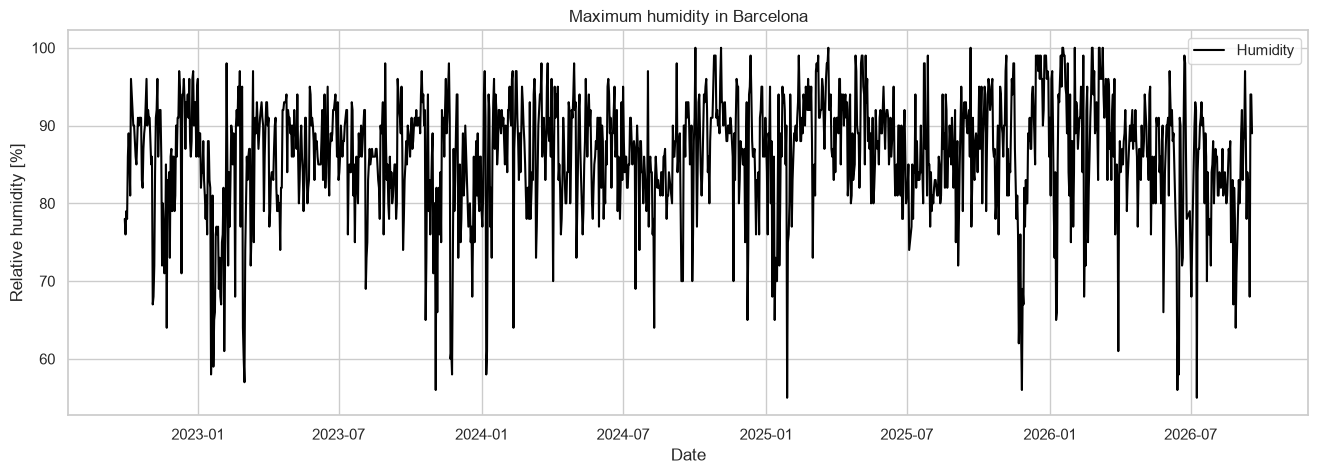

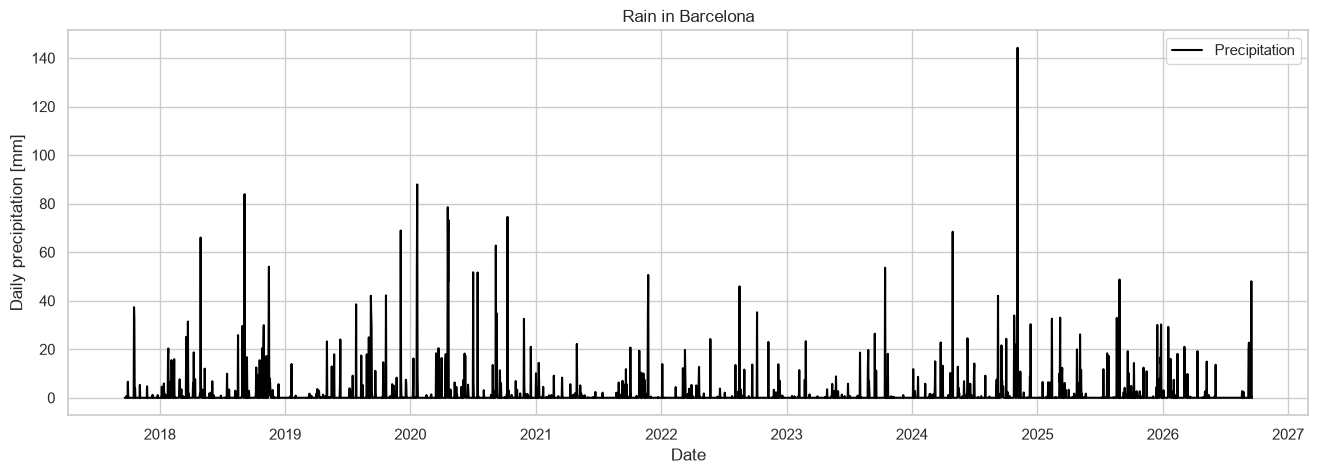

In [14]:
# LEAVE AS-IS

# Retrieve the last 9 years
weather_sample = weather_indexed.tail(9*365)

# Plot temperature
plot_min_max(weather_sample, title='Temperatures in Barcelona', ylabel='Temperature [C]',
             min_col='temp_min', max_col='temp_max', avg_col='temp_avg')

# Plot humidity
plot_variable(weather_sample, title='Maximum humidity in Barcelona', ylabel='Relative humidity [%]',
             col='relhumidity_max', label='Humidity')

# Plot precipitation
plot_variable(weather_sample, title='Rain in Barcelona', ylabel='Daily precipitation [mm]', 
            col='rainfall', label='Precipitation')


<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

Do you observe seasonality in these plots? If yes, in which one(s)? Which type of seasonality (weekly, monthly, yearly)?

* Yes, I can clearly observe yearly seasonality in the temperature plot. Temperatures are higher during summer and lower during winter, and this pattern repeats every year. This shows an annual cycle.

In which plot(s) you do not observe seasonality? Why do you think that happens, if weather is supposed to be cyclical?

* I do not observe a clear seasonal pattern in the humidity and precipitation plots. Humidity changes frequently throughout the year, while rainfall is irregular, with some days having no rain and others having heavy rainfall. Although weather is cyclical, these variables are more irregular and their seasonal patterns are not as easy to see in daily data.


## 1.3. Smoothing <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Implement the moving_average function.**</font>

In [ ]:
def moving_average(df, window_size):

    averages = []
    length = len(df)
    
    for i in range(length):

        # YOUR ANSWER HERE
        # Select the previous window_size rows
        start = max(0, i - window_size + 1)  # AI assistance: avoid negative indices
        window = df.iloc[start:i + 1]
        # Calculate the average of each column
        averages.append(window.mean(numeric_only=True))

    smoothed = pd.DataFrame(averages, columns=df.columns)
    smoothed.set_index(df.index, inplace=True)
    
    return smoothed

In [20]:
# LEAVE AS-IS

window_size = 7
weather_smoothed = moving_average(weather_sample, window_size)

display(weather_sample.head(10))
display(weather_smoothed.head(10))

,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
date,,,,,,,,,,,,,,,
2017-09-21,20.8,0.0,17.0,24.7,22.0,3.6,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-22,20.8,0.0,19.0,22.7,99.0,1.7,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-23,21.2,0.0,18.5,24.0,20.0,3.3,8.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-24,22.6,0.0,20.0,25.1,22.0,3.1,10.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-25,21.2,0.0,18.8,23.6,10.0,5.3,13.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-26,21.2,0.7,18.6,23.7,20.0,3.3,8.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-27,21.0,0.0,18.4,23.5,20.0,3.6,7.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-28,21.8,0.0,19.1,24.6,19.0,3.1,5.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-29,21.0,0.0,18.5,23.6,19.0,3.3,7.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,temp_avg,rainfall,temp_min,temp_max,windspeed_dir,windspeed_avg,windspeed_gusts,sun,pressure_max,pressure_min,relhumidity_mean,relhumidity_max,relhumidity_min,pintMax,horaPIntMax
date,,,,,,,,,,,,,,,
2017-09-21,20.800000,0.000000,17.000000,24.700000,22.000000,3.600000,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-22,20.800000,0.000000,18.000000,23.700000,60.500000,2.650000,8.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-23,20.933333,0.000000,18.166667,23.800000,47.000000,2.866667,8.533333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-24,21.350000,0.000000,18.625000,24.125000,40.750000,2.925000,8.975000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-25,21.320000,0.000000,18.660000,24.020000,34.600000,3.400000,9.800000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-26,21.300000,0.116667,18.650000,23.966667,32.166667,3.383333,9.550000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-27,21.257143,0.100000,18.614286,23.900000,30.428571,3.414286,9.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-28,21.400000,0.100000,18.914286,23.885714,30.000000,3.342857,8.628571,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-09-29,21.428571,0.100000,18.842857,24.014286,18.571429,3.571429,8.585714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


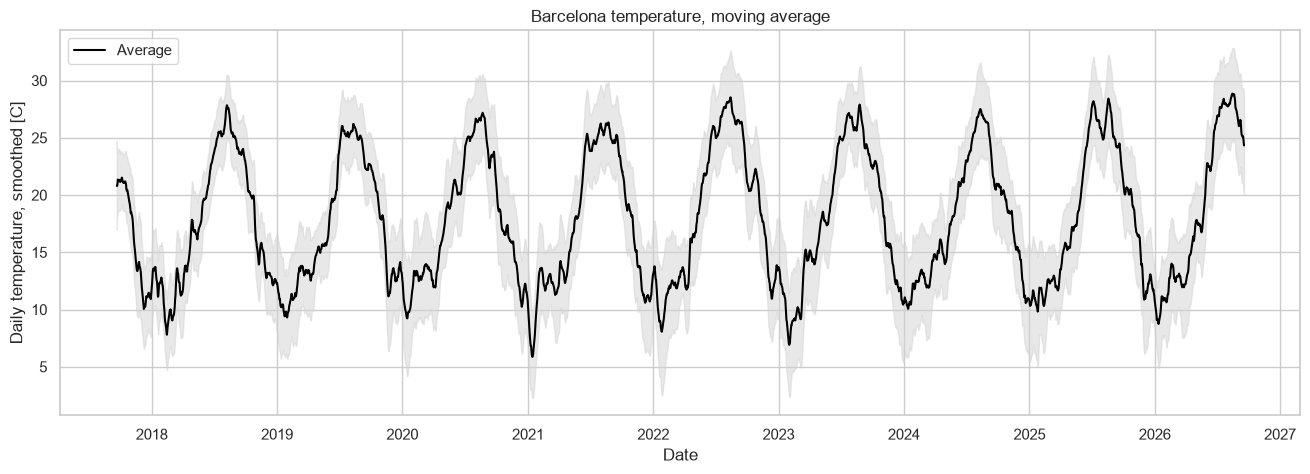

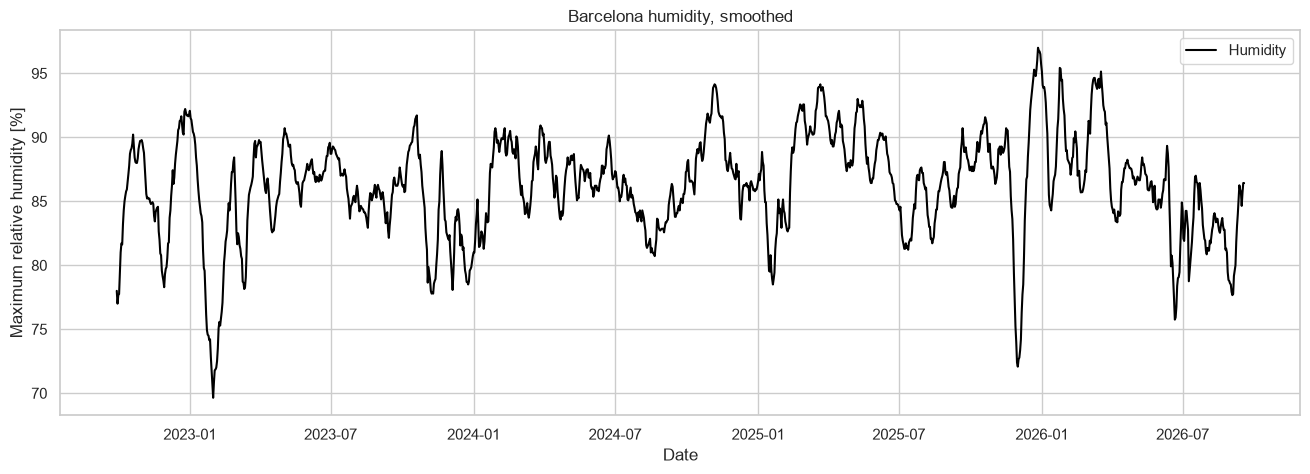

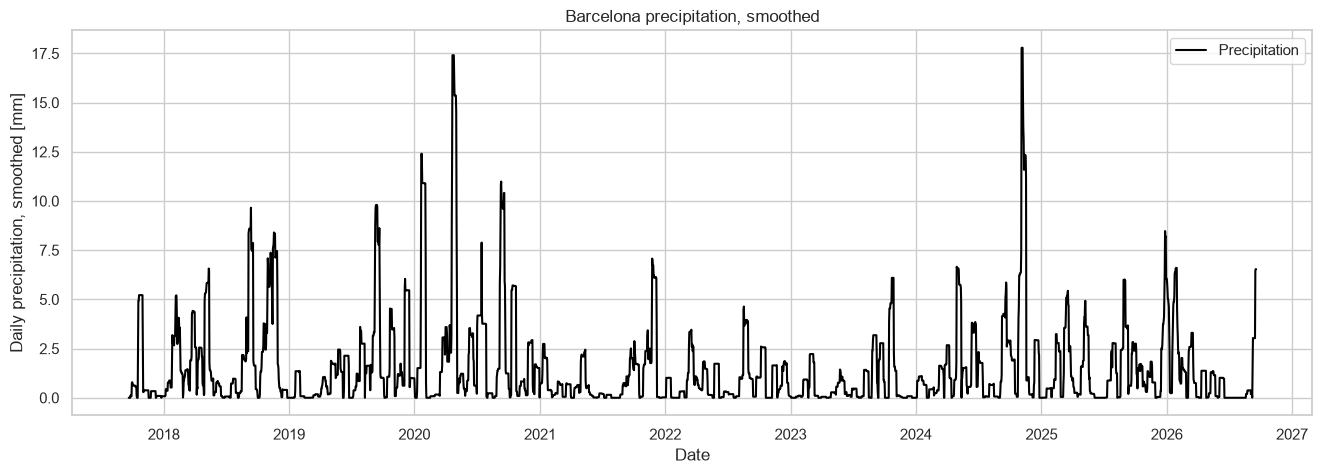

In [21]:
# LEAVE AS-IS

# Smooth over two weeks
weather_smoothed = moving_average(weather_sample, 14)

# Plot smoothed temperature
plot_min_max(weather_smoothed, ylabel='Daily temperature, smoothed [C]',
             title="Barcelona temperature, moving average", 
             min_col='temp_min', max_col='temp_max', avg_col='temp_avg')

# Plot smoothed humidity
plot_variable(weather_smoothed,
              title="Barcelona humidity, smoothed", 
                col="relhumidity_max", label="Humidity", ylabel="Maximum relative humidity [%]")

# Plot smoothed precipitation
plot_variable(weather_smoothed,
              title="Barcelona precipitation, smoothed", 
                col="rainfall", label="Precipitation", ylabel="Daily precipitation, smoothed [mm]")

<font size="+1" color="#2680EB">**Answer the following questions**</font>


**Answer:**

What is the main difficulty when implementing moving averages?

* The main difficulty is choosing the right window size and handling the beginning of the time series. If the window is too small, the series remains noisy and the underlying patterns are difficult to identify. On the other hand, if the window is too large, important short-term variations and peaks may disappear. Also, at the beginning of the series, there are not enough previous observations to fill the entire window, so we need to use the available data.

Do you have some new observation in the humidity series? Does it change your assessment regarding seasonality when you look at the smoothed series versus the original one.

* Yes, the smoothed series makes the changes in humidity easier to identify because it reduces daily fluctuations. We can see clearer increases and drops, especially during some winter periods, such as in 2023 and 2025. However, the patterns are not repeated regularly at the same time every year. Therefore, my assessment does not change: there may be some yearly variations, but there is no clear or consistent yearly seasonality in humidity, unlike in the temperature series.

# 2. Forecasting

## 2.1. Create auto-correlation plots <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement the lagged_series computation**</font>

In [ ]:
def lagged_series(series, lag):
    original_trimmed = []
    lagged = []
    
    for i in range(len(series)):
        j = i - lag
        # YOUR ANSWER HERE
        #AI: to understand the idea
        # Keep values that have a previous observation
        if j >= 0:
            original_trimmed.append(series.iloc[i])
            lagged.append(series.iloc[j])
        
    return original_trimmed, lagged  

In [28]:
# LEAVE AS-IS

assert ([44, 55, 66, 77, 88], [11, 22, 33, 44, 55]) == lagged_series(pd.Series([11,22,33,44,55,66,77,88]), 3)

assert ([33, 44, 55, 66, 77, 88], [11, 22, 33, 44, 55, 66]) == lagged_series(pd.Series([11,22,33,44,55,66,77,88]), 2)

assert ([22, 33, 44, 55, 66, 77, 88], [11, 22, 33, 44, 55, 66, 77]) == lagged_series(pd.Series([11,22,33,44,55,66,77,88]), 1)


In [29]:
# LEAVE AS-IS

# Computes the correlation between two vectors,
# but first removes positions in which any of the vectors is a NaN
def correlation_without_nan(x,y):
    positions_to_remove = ~np.logical_or(np.isnan(x), np.isnan(y))

    x_without_nan = np.compress(positions_to_remove, x)
    y_without_nan = np.compress(positions_to_remove, y)
    return stats.pearsonr(x_without_nan,y_without_nan)[0]  

# Compute autocorrelation
def autocorrelation(series, lag):
    x,y = lagged_series(series, lag)
            
    return correlation_without_nan(x,y)

<font size="+1" color="#2680EB">**Implement the compute_autocorrelations function.** This computes all auto-correlations of the series from period 0 to max_periods-1.</font>

In [ ]:
def compute_autocorrelations(series, max_periods):
    correlations = []

    # YOUR ANSWER HERE
    # Calculate the autocorrelation for each lag
    for lag in range(max_periods):
        correlations.append(autocorrelation(series, lag))

    
    return correlations


In [31]:
# LEAVE AS-IS

# Compute for up to 2 years
max_periods = 2*365

# Compute autocorrelations of max temperature, average temperature, relative humidity, and rainfall
print("Computing autocorrelations of the maximum temperature series")
auto_correlations_temp_max = compute_autocorrelations(weather_sample['temp_max'], max_periods)

print("Computing autocorrelations of the average temperature series")
auto_correlations_temp_avg = compute_autocorrelations(weather_sample['temp_avg'], max_periods)

print("Computing autocorrelations of the relative humidity series")
auto_correlations_relhumidity = compute_autocorrelations(weather_sample['relhumidity_max'], max_periods)

print("Computing autocorrelations of the rainfall series")
auto_correlations_rainfall = compute_autocorrelations(weather_sample['rainfall'], max_periods)

Computing autocorrelations of the maximum temperature series
Computing autocorrelations of the average temperature series
Computing autocorrelations of the relative humidity series
Computing autocorrelations of the rainfall series


In [32]:
# LEAVE AS-IS

def plot_auto_correlations(correlations, xlabel="Lag (days)", ylabel="Autocorrelation"):

    # The instructor used Gemini to create this plot using seaborn

    # Apply Seaborn aesthetic theme
    sns.set_theme(style='whitegrid')

    # Figure
    plt.figure(figsize=(15, 4))

    # Plot correlation using Seaborn
    sns.lineplot(x=range(len(correlations)), y=correlations)

    # Add xticks every 10 periods
    plt.xticks(np.arange(0, len(correlations), 10), rotation=90)

    # Add a horizontal line at zero
    plt.axhline(0, color='black', linestyle='--', alpha=0.7)

    # Add labels
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.show()

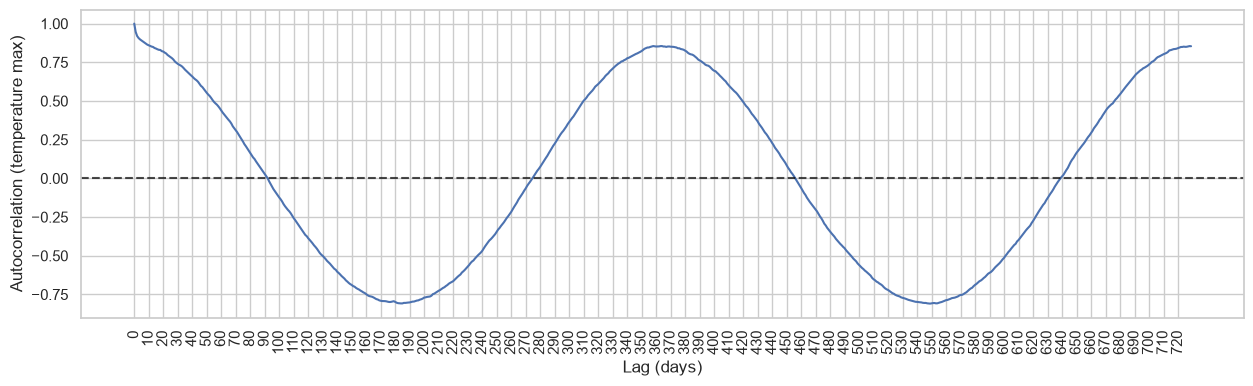

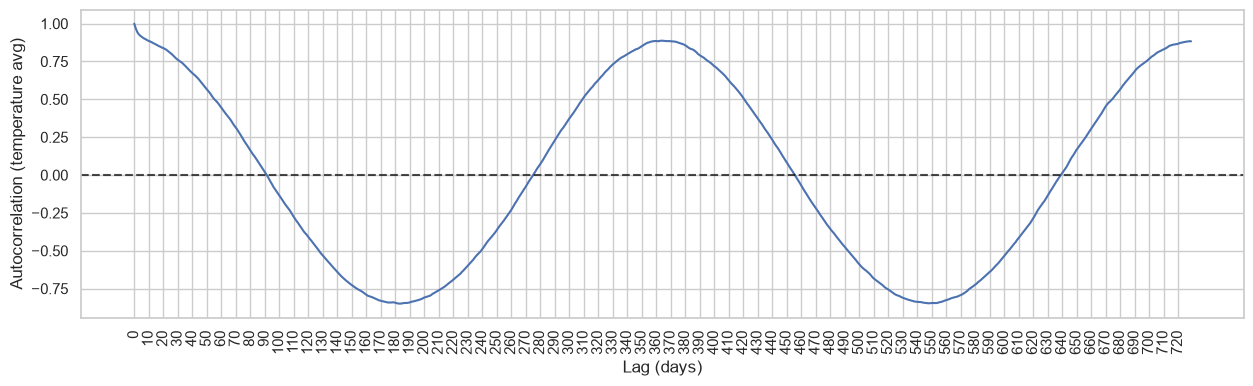

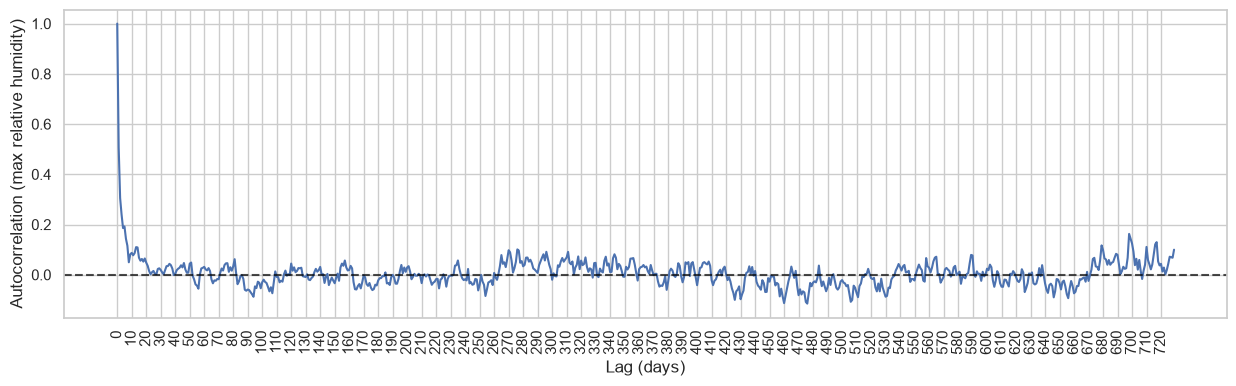

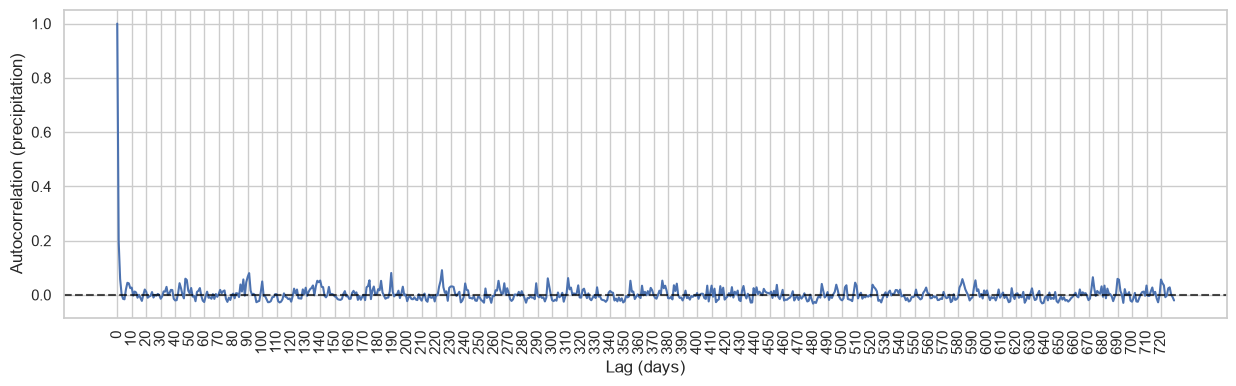

In [33]:
# LEAVE AS-IS

# Plot max temperature auto-correlation
plot_auto_correlations(auto_correlations_temp_max, ylabel="Autocorrelation (temperature max)")

# Plot avg temperature auto-correlation
plot_auto_correlations(auto_correlations_temp_avg, ylabel="Autocorrelation (temperature avg)")

# Plot max relative humidity auto-correlation
plot_auto_correlations(auto_correlations_relhumidity, ylabel="Autocorrelation (max relative humidity)")

# Plot precipitation auto-correlation
plot_auto_correlations(auto_correlations_rainfall, ylabel="Autocorrelation (precipitation)")

<font size="+1" color="#2680EB">**Answer the following questions.**</font>


**Answer:**

What do these autocorrelations indicate about the temperature data?

* The temperature data shows a strong yearly seasonal pattern. The autocorrelation decreases and becomes negative after approximately half a year, then increases again and reaches a positive peak around 365 days. This pattern repeats after another year, which indicates that temperatures are strongly related to the same period in previous years.

What do these autocorrelations indicate about the humidity data, when comparing them to the autocorrelations on the precipitation data?

* Humidity shows slightly more autocorrelation than precipitation. Although both series decrease quickly towards zero, humidity still presents some small positive and negative correlations at different lags. Precipitation stays much closer to zero, which indicates that its values are less related to previous days. Neither series shows a clear yearly pattern like temperature.

Based on what you see in the autocorrelation plot, what is more unpredictable, humidity or precipitation?

* Precipitation is more unpredictable than humidity because its autocorrelation drops very quickly towards zero. This means that previous rainfall values provide very little information about future rainfall. Humidity also has low autocorrelation, but it shows slightly more dependence on previous values.

## 2.2. Prepare for learning an auto-regressive model <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Implement the function prepare_matrices.** It should create a matrix with the coefficient of the system of equations that the forecasting model must solve.</font>

In [ ]:
def prepare_matrices(series, lags):
    y = []
    X = []
    series_values = np.asarray(series)
    
    for lag in lags:
        assert(lag > 0)
        assert(lag < len(series_values))
    
    for i in range(np.max(lags), len(series_values)):
        # YOUR ANSWER HERE
        # Get the values from the selected previous lags
        row = [series_values[i - lag] for lag in lags]

        # Get the current value
        target = series_values[i]
        
        # AI assistance was used to check the NaN handling.
        # Skip equations containing NaN values
        if not np.isnan(row).any() and not np.isnan(target):
            X.append(row)
            y.append(target)
        
    return X, y

In [35]:
# LEAVE AS-IS

X, y = prepare_matrices([11, 15, 32, 37, 52, 54, 70, 89], [2, 3])
assert X == [[15, 11], [32, 15], [37, 32], [52, 37], [54, 52]]
assert y == [37, 52, 54, 70, 89]

X, y = prepare_matrices([11, 15, np.nan, 37, 52, 54, 70, 89], [2, 3])
assert X == [[15, 11], [52, 37], [54, 52]]
assert y == [37, 70, 89]

## 2.3. Perform forecasts <font color="#2680EB">[20%]</font>

In [36]:
# LEAVE AS-IS

def perform_forecast(series, lags):

    # Prepare matrices for linear regression
    X, y = prepare_matrices(series, lags)

    # Perform forecast
    linear_regressor = LinearRegression()
    linear_regressor.fit(X,y)
    y_pred = linear_regressor.predict(X)

    # Compute forecasting error

    # Normalized root mean square deviation (NRMSD)
    rmse = math.sqrt(mean_squared_error(y, y_pred))/(np.max(y)-np.min(y))

    # Maximum absolute difference
    max_absolute_diff = np.max(np.abs(y - y_pred))
    
    # Return: observed, predicted, error
    return (y, y_pred, rmse, max_absolute_diff)

In [37]:
# LEAVE AS-IS

def plot_forecast(y, y_pred, xlabel="Period", ylabel="", nrmsd=np.nan):

    plt.figure(figsize=(15, 4))
    periods = range(len(y))

    # The instructor used Gemini to create this plot using seaborn
    sns.lineplot(x=periods, y=y, color='gray', marker='.', linewidth=4,
                 label='Observed')
    sns.lineplot(x=periods, y=y_pred, color='green', linestyle='--',
                 linewidth=2,
                 label=('Model (NRMSD=%.2f)' % nrmsd if not np.isnan(nrmsd) else 'Model'))

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend()
    plt.show()

<font size="+1" color="#2680EB">**Indicate your choice of lags in the next cell,** as array lags_daily_temperature</font>

In [38]:
# AI assistance was used to select the lags based on the autocorrelation plots.
lags_daily_temperature = [1, 2, 3, 365]

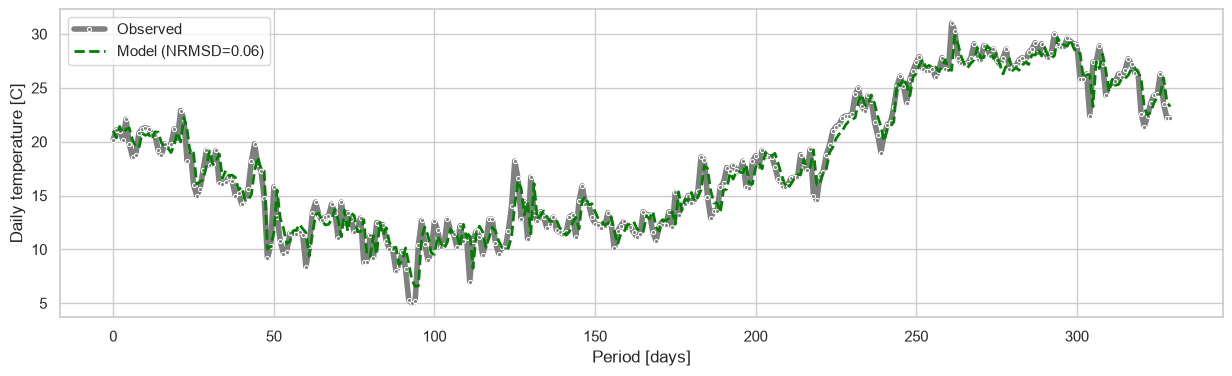

In [ ]:
# LEAVE AS-IS
# Plot predicted and actual temperature in the last 720 days of the sample

(y, y_pred, nrmsd, maxdiff) = perform_forecast(weather_sample['temp_avg'][-720:],
                                      lags_daily_temperature)

plot_forecast(y, y_pred,
              xlabel="Period [days]",
              ylabel="Daily temperature [C]",
              nrmsd=nrmsd)

<font size="+1" color="#2680EB">**Answer the following questions.**</font>


**Answer:**

How accurate are your predictions? What is the maximum difference between the temperature you predict and the one that you observe? 

* The predictions are quite accurate, as the model follows the observed temperatures very closely. The NRMSD is 0.06 (6%), which indicates a relatively small prediction error. The predicted values are very similar to the actual values, although there are some small differences.

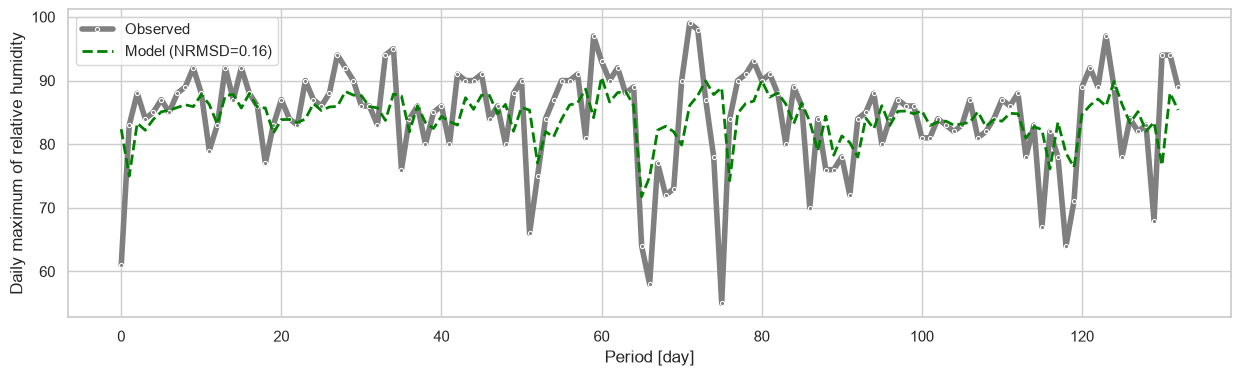

In [43]:
# AI assistance was used to select the lags based on the autocorrelation plot.
lags_relhumidity_max = [1, 2, 3, 7]

# LEAVE AS-IS
(y, y_pred, nrmsd, maxdiff) = perform_forecast(weather_sample['relhumidity_max'][-180:],
                                      lags_relhumidity_max)

plot_forecast(y, y_pred,
              xlabel="Period [day]",
              ylabel="Daily maximum of relative humidity",
              nrmsd=nrmsd)

<font size="+1" color="#2680EB">**Answer the following questions.**</font>


**Answer:**

How accurate is your prediction of relative humidity? How is this in comparison to your prediction of daily temperature?

* The prediction of relative humidity is not very accurate, with an NRMSD of 0.16 (16%). Visually, the model captures the general level of the series, but it fails to follow the sharp daily drops and sudden fluctuations. Its predictions are much smoother than the observed values. Compared to daily temperature, the prediction is clearly worse. The temperature model achieved a much lower NRMSD of 0.06 (6%) and followed the actual values much more closely. This difference makes sense when looking at the autocorrelation plots: temperature has strong autocorrelation and a clear yearly seasonal pattern, while relative humidity has much weaker autocorrelation and more daily fluctuations. Therefore, humidity is harder to predict using an autoregressive model.

<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that my answers were not written by an AI-enabled code assistant, and that except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>